# 5.1 observify, simply

Turns a clean (SSD) and a contaminated (facular band) actress spectrum into HARPS-resolution spectra and forms their spectral ratio (SRA) as in Costes et al. 2026 ([arXiv:2607.06339](https://arxiv.org/abs/2607.06339)). One cell per step, in order:

1. settings
2. load the two fluxes
3. convolve to R = 115,000
4. SNR array and noise
5. normalise each spectrum to its peak
6. ratio
7. plots
8. SRA residual at SNR 200, 500, 1000 and 3000

All wavelengths are vacuum (the simulation's frame). Run from `actress_highres/actress/`.


In [1]:
# ===== 1. settings =====
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

speed_of_light = 299792.458   # km/s

# Spectra simulated in 1_gridsearch (real SSD + 200G facula, v_eq 4000 m/s); names are <geometry>_ff<ff>_i<inc>
cache_file = './outputs/gridsearch/1_gridsearch_v4000_res3d5_res2d200_4300.1_4399.9_randomseed0_incs0-90x10.npz'
contaminated_name = 'equatorial_ff0.10_i90'
clean_name = 'quiet_i90'   # the clean star at the SAME inclination

# HARPS: R = 115,000 (Mayor et al. 2003, The Messenger 114, 20;
# https://www.hq.eso.org/sci/facilities/lasilla/instruments/harps/science/papers/harps_mess114.pdf)
resolution = 115000   # spectra stay on the simulation grid, not resampled onto HARPS pixels

# Noise: snr is the SNR per simulation bin at the continuum (peak flux), at these wavelengths. An estimate only:
# a HARPS pixel is ~1.35 simulation bins wide
snr = 1000                  # choose 200-3000
seed_active = 1             # noise seed for the contaminated (active) spectrum
seed_inactive = 2           # noise seed for the clean (inactive) spectrum
if not 200 <= snr <= 3000:
    raise ValueError(f"snr = {snr} is outside 200-3000")

# Flattening left out for now. Paper (Sec. 2.2, p. 5) divides the ratio by its smoothing, "applying a Gaussian
# filter with sigma = 15 pixels" (HARPS pixels: ~12 km/s, ~20 simulation bins), to remove slow trends

# The paper's Fig. 1 window (4367.5-4382.5 A air) and its features (Fe I 4375.9, 4378.3, 4379.2 A air), in vacuum
plot_window = (4368.73, 4383.73)                                                   # A
paper_features = {'Fe I 4375.9': 4377.159, '4378.3': 4379.514, '4379.2': 4380.460}   # A; keys are air

def mark_paper_features(ax):
    for feature_wavelength in paper_features.values():
        ax.axvline(feature_wavelength, color='tab:blue', linestyle=':', linewidth=0.8)

equatorial_ff0.10_i90 (visible ff 0.093) and quiet_i90: 11457 bins, 4300.17-4399.83 A


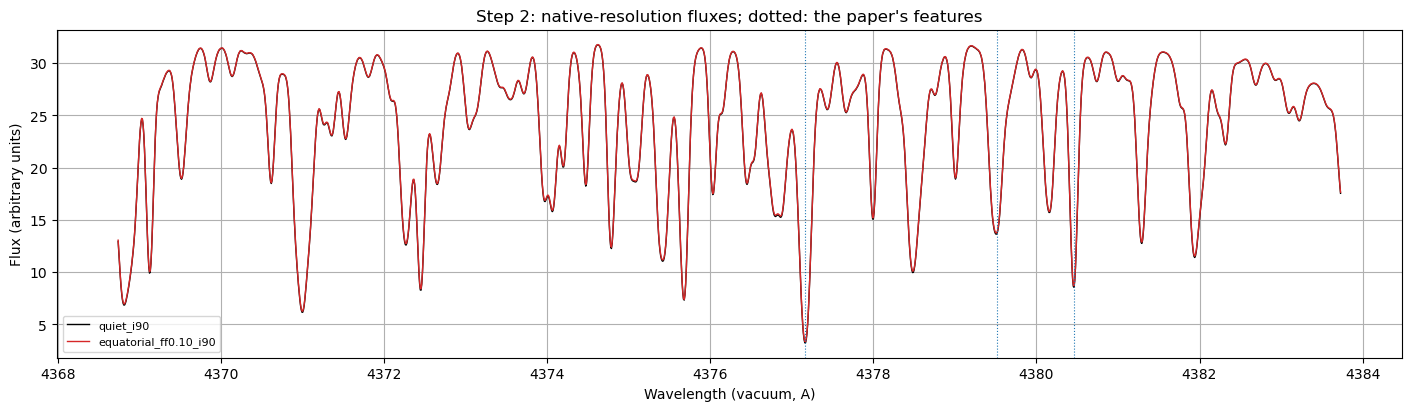

In [2]:
# ===== 2. load the two fluxes =====
cache = np.load(cache_file)
wavelength = cache[f'bins_{contaminated_name}']   # A, vacuum, log-uniform at R = 500,000
if not np.array_equal(wavelength, cache[f'bins_{clean_name}']):
    raise ValueError(f"{contaminated_name} and {clean_name} are on different bins: different inclinations?")
flux_active = cache[f'spectrum_{contaminated_name}']   # arbitrary units
flux_inactive = cache[f'spectrum_{clean_name}']
for name, flux in ((contaminated_name, flux_active), (clean_name, flux_inactive)):
    if not np.all(np.isfinite(flux)) or np.any(flux <= 0):
        raise ValueError(f"{name}: non-finite or non-positive flux")
visible_ff = dict(zip(cache['run_names'], cache['visible_ffs']))[contaminated_name]
print(f"{contaminated_name} (visible ff {visible_ff:.3f}) and {clean_name}: {len(wavelength)} bins, "
      f"{wavelength[0]:.2f}-{wavelength[-1]:.2f} A")

in_window_native = (wavelength >= plot_window[0]) & (wavelength <= plot_window[1])
fig, ax = plt.subplots(figsize=(14, 4), constrained_layout=True)
ax.plot(wavelength[in_window_native], flux_inactive[in_window_native], color='k', linewidth=1, label=clean_name)
ax.plot(wavelength[in_window_native], flux_active[in_window_native], color='tab:red', linewidth=1, label=contaminated_name)
mark_paper_features(ax)
ax.set_xlabel('Wavelength (vacuum, A)')
ax.set_ylabel('Flux (arbitrary units)')
ax.set_title('Step 2: native-resolution fluxes; dotted: the paper\'s features')
ax.grid(True)
ax.legend(fontsize=8)
plt.show()

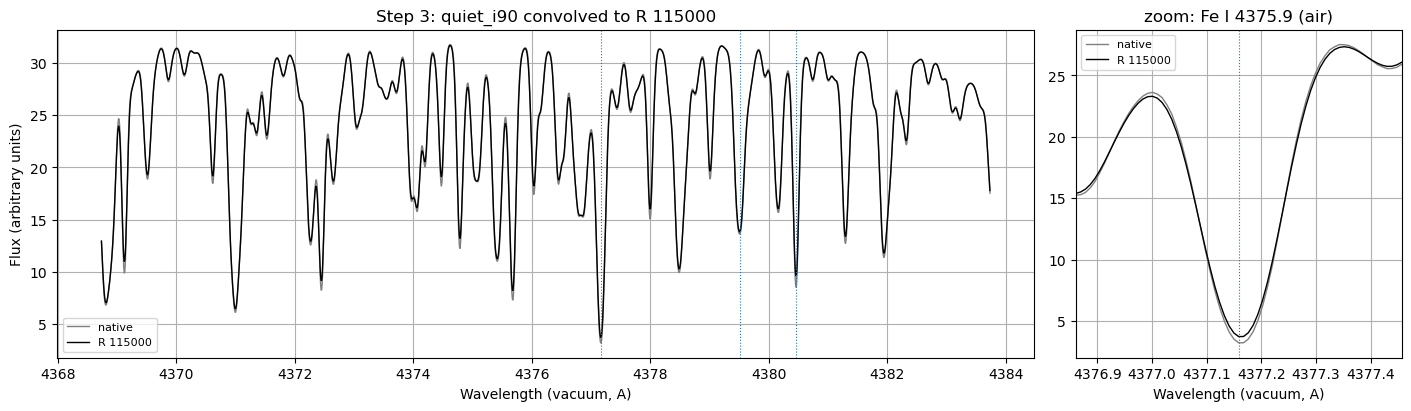

In [3]:
# ===== 3. convolve to R = 115,000 =====
# Gaussian convolution of FWHM reference_wavelength / R, converted to bins with the mean wavelength step
reference_wavelength = 4360   # A, vacuum
convolution_fwhm = reference_wavelength / resolution   # A
convolution_sigma = convolution_fwhm / (2 * np.sqrt(2 * np.log(2)))   # A
wavelength_step = np.mean(np.diff(wavelength))   # A
convolution_sigma_bins = convolution_sigma / wavelength_step
convolved_active = gaussian_filter1d(flux_active, convolution_sigma_bins, mode='nearest')
convolved_inactive = gaussian_filter1d(flux_inactive, convolution_sigma_bins, mode='nearest')
# No edge trim: the outer ~6 bins at each end are averaged with mode='nearest' padding (SRA error < 1e-4)
#print(f"Convolution FWHM {convolution_fwhm * 1000:.2f} mA at {reference_wavelength} A = {convolution_sigma_bins * 2.3548:.2f} bins")

near_fe_native = np.abs(wavelength - paper_features['Fe I 4375.9']) < 0.3
fig, axes = plt.subplots(1, 2, figsize=(14, 4), constrained_layout=True, gridspec_kw={'width_ratios': [3, 1]})
for ax, selection in zip(axes, (in_window_native, near_fe_native)):
    ax.plot(wavelength[selection], flux_inactive[selection], color='grey', linewidth=1, label='native')
    ax.plot(wavelength[selection], convolved_inactive[selection], color='k', linewidth=1, label=f'R {resolution}')
    mark_paper_features(ax)
    ax.set_xlabel('Wavelength (vacuum, A)')
    ax.grid(True)
    ax.legend(fontsize=8)
axes[0].set_ylabel('Flux (arbitrary units)')
axes[0].set_title(f'Step 3: {clean_name} convolved to R {resolution}')
axes[1].set_title('zoom: Fe I 4375.9 (air)')
axes[1].set_xlim(wavelength[near_fe_native][0], wavelength[near_fe_native][-1])
plt.show()

[640.13166737 612.21015747 584.35972537 ... 779.20336892 763.24005665
 749.04208216] 31.903861732255564 [13.07319921 11.95760812 10.8944123  ... 19.37068138 18.58512835
 17.90010958]
SNR per bin: 1000 at the continuum, 256 in the deepest line core


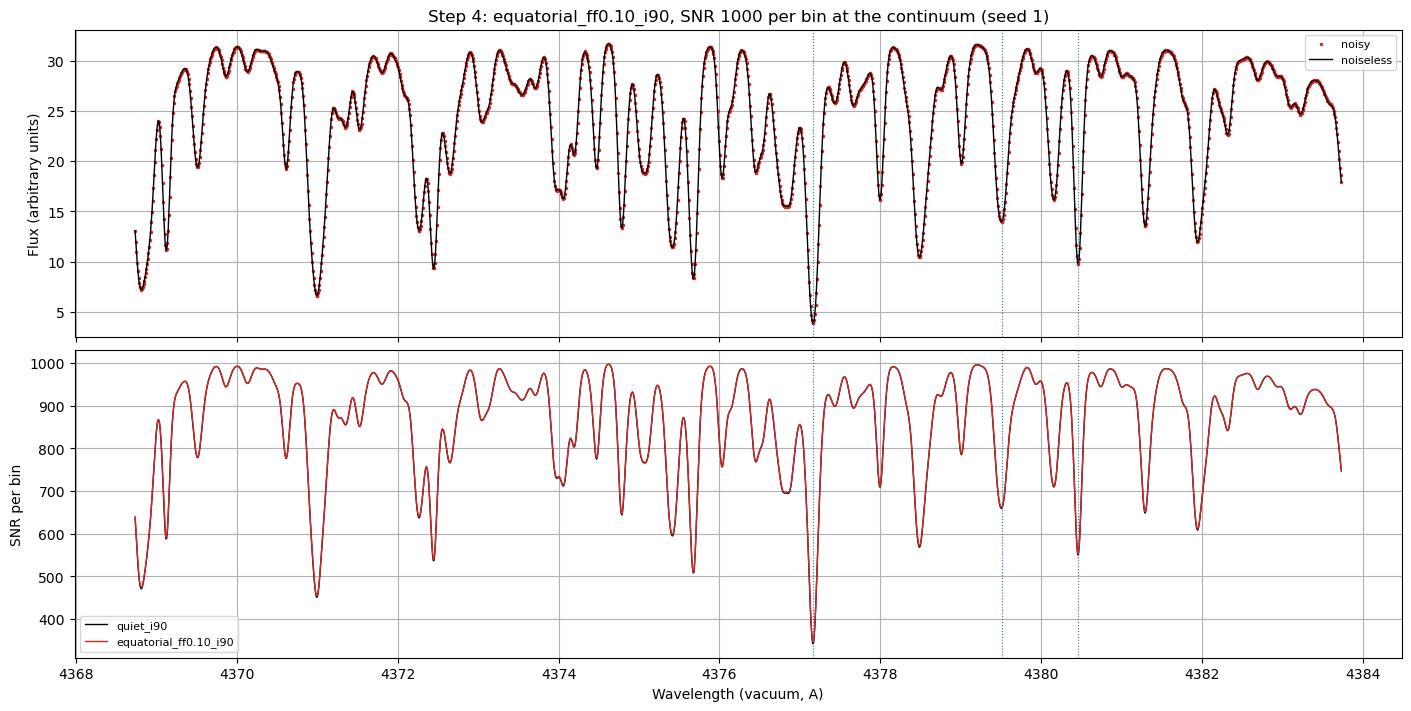

In [4]:
# ===== 4. SNR array and noise =====
# Photon noise: SNR goes as sqrt(counts), so each bin's SNR is snr x sqrt(flux / peak flux) and line cores are
# noisier. Each spectrum gets its own noise draws (seed_active, seed_inactive).
snr_active = snr * np.sqrt(convolved_active / convolved_active.max()) 
in_window = (wavelength >= plot_window[0]) & (wavelength <= plot_window[1])
print(snr_active[in_window], convolved_active.max(), convolved_active[in_window])
snr_inactive = snr * np.sqrt(convolved_inactive / convolved_inactive.max())
noisy_active = convolved_active + np.random.default_rng(seed_active).normal(0, convolved_active / snr_active)
noisy_inactive = convolved_inactive + np.random.default_rng(seed_inactive).normal(0, convolved_inactive / snr_inactive)
print(f"SNR per bin: {snr} at the continuum, {snr_active.min():.0f} in the deepest line core")

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True, constrained_layout=True)
axes[0].plot(wavelength[in_window], noisy_active[in_window], '.', color='tab:red', markersize=3, label='noisy')
axes[0].plot(wavelength[in_window], convolved_active[in_window], color='k', linewidth=1, label='noiseless')
axes[0].set_ylabel('Flux (arbitrary units)')
axes[0].set_title(f'Step 4: {contaminated_name}, SNR {snr} per bin at the continuum (seed {seed_active})')
axes[1].plot(wavelength[in_window], snr_inactive[in_window], color='k', linewidth=1, label=clean_name)
axes[1].plot(wavelength[in_window], snr_active[in_window], color='tab:red', linewidth=1, label=contaminated_name)
axes[1].set_ylabel('SNR per bin')
axes[1].set_xlabel('Wavelength (vacuum, A)')
for ax in axes:
    mark_paper_features(ax)
    ax.grid(True)
    ax.legend(fontsize=8)
plt.show()

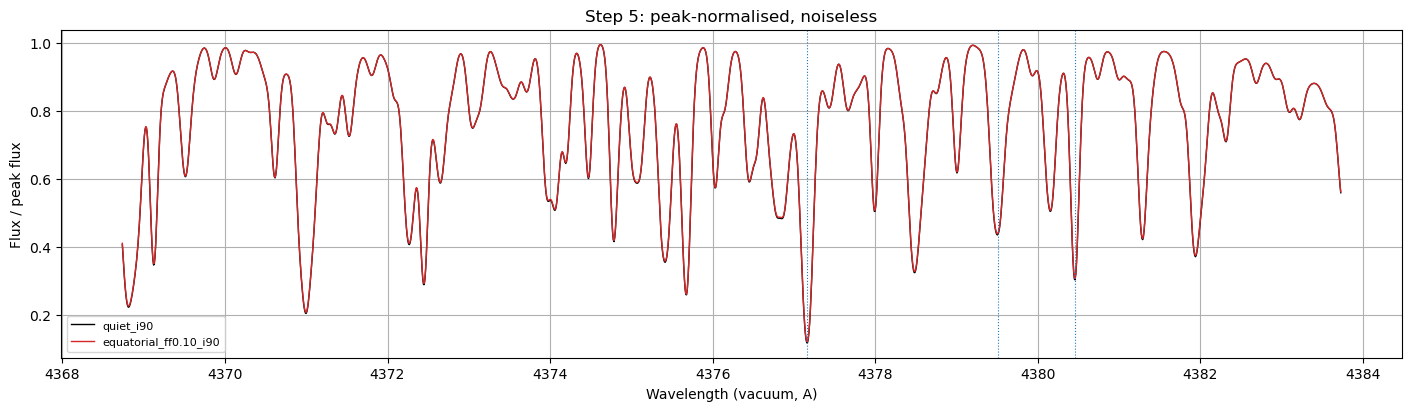

In [5]:
# ===== 5. normalise each spectrum to its peak =====
# Paper (Sec. 2.2, p. 3): "each order of these nightly or seasonal spectra was normalised to one using the peak of
# the flux". The whole window is treated as one order. Without flattening, the two peak fluxes set the zero point
# of the SRA residual.
def peak_normalised(flux):
    return flux / flux.max()


norm_active, norm_inactive = peak_normalised(noisy_active), peak_normalised(noisy_inactive)
norm_active_noiseless, norm_inactive_noiseless = peak_normalised(convolved_active), peak_normalised(convolved_inactive)

fig, ax = plt.subplots(figsize=(14, 4), constrained_layout=True)
ax.plot(wavelength[in_window], norm_inactive_noiseless[in_window], color='k', linewidth=1, label=clean_name)
ax.plot(wavelength[in_window], norm_active_noiseless[in_window], color='tab:red', linewidth=1,
        label=contaminated_name)
mark_paper_features(ax)
ax.set_xlabel('Wavelength (vacuum, A)')
ax.set_ylabel('Flux / peak flux')
ax.set_title('Step 5: peak-normalised, noiseless')
ax.grid(True)
ax.legend(fontsize=8)
plt.show()

Fe I 4375.9 (air): truth 0.0372, observified 0.0304, noise 0.0041 (7.4 sigma)


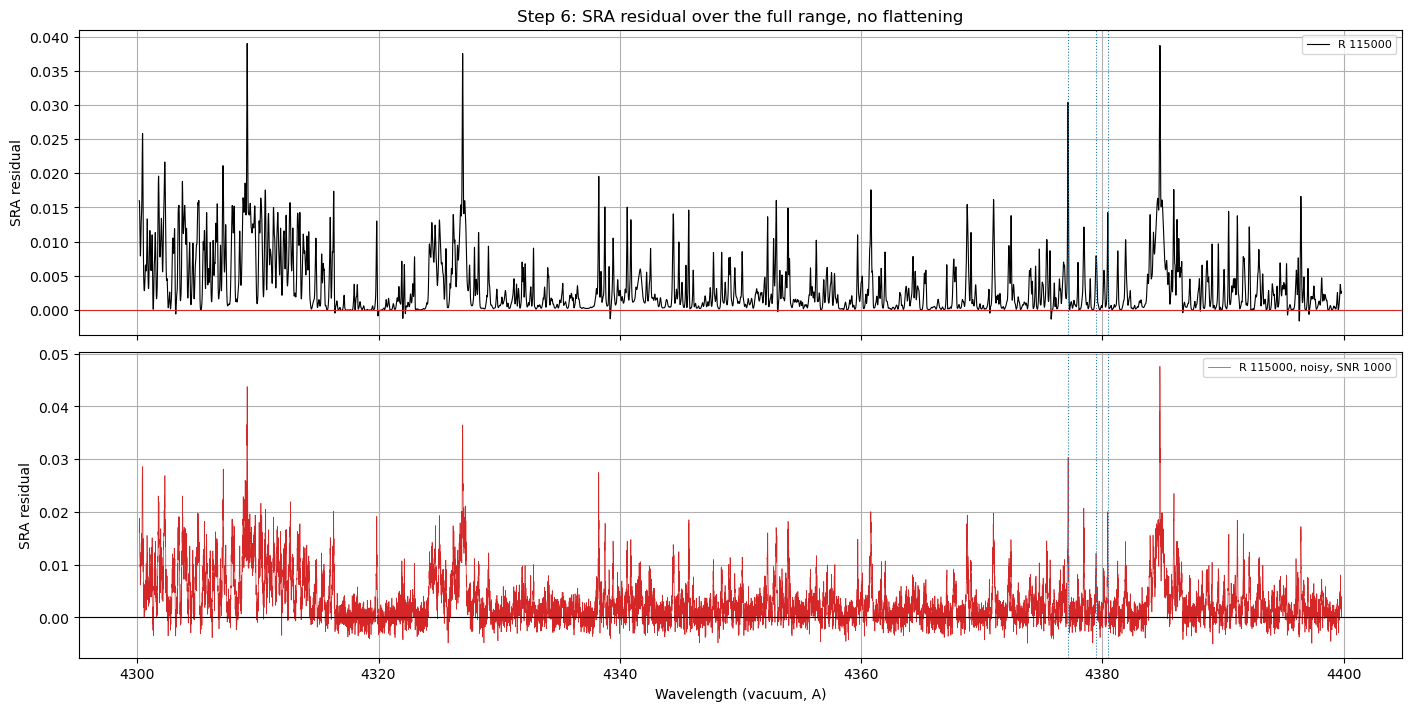

In [6]:
# ===== 6. ratio =====
# Paper (Sec. 2.2): ratio = active / low-activity template, then flattened (see the note in step 1). Flattening is left
# out for now, so slow trends stay in. SRA residual = ratio - 1.
def sra_residual(active, inactive):
    return active / inactive - 1


sra_noisy = sra_residual(norm_active, norm_inactive)
sra_noiseless = sra_residual(norm_active_noiseless, norm_inactive_noiseless)
sra_sigma = np.sqrt(1 / snr_active ** 2 + 1 / snr_inactive ** 2)   # 1-sigma noise of the ratio
truth = flux_active / flux_inactive - 1                            # native resolution, no instrument or processing

near_fe = np.abs(wavelength - paper_features['Fe I 4375.9']) < 0.1
peak = np.argmax(np.where(near_fe, sra_noiseless, -np.inf))
print(f"Fe I 4375.9 (air): truth {truth[np.abs(wavelength - paper_features['Fe I 4375.9']) < 0.1].max():.4f}, "
      f"observified {sra_noiseless[peak]:.4f}, noise {sra_sigma[peak]:.4f} ({sra_noiseless[peak] / sra_sigma[peak]:.1f} sigma)")

# Full range, so the slow baseline that flattening would remove is visible; noisy in its own panel so it doesn't cover it
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True, constrained_layout=True)
axes[0].plot(wavelength, sra_noiseless, color='k', linewidth=0.8, label=f'R {resolution}')
axes[0].axhline(0, color='tab:red', linewidth=0.8)
axes[0].set_title('Step 6: SRA residual over the full range, no flattening')
axes[1].plot(wavelength, sra_noisy, color='tab:red', linewidth=0.5, label=f'R {resolution}, noisy, SNR {snr}')
axes[1].axhline(0, color='k', linewidth=0.8)
axes[1].set_xlabel('Wavelength (vacuum, A)')
for ax in axes:
    mark_paper_features(ax)
    ax.set_ylabel('SRA residual')
    ax.grid(True)
    ax.legend(fontsize=8)
plt.show()

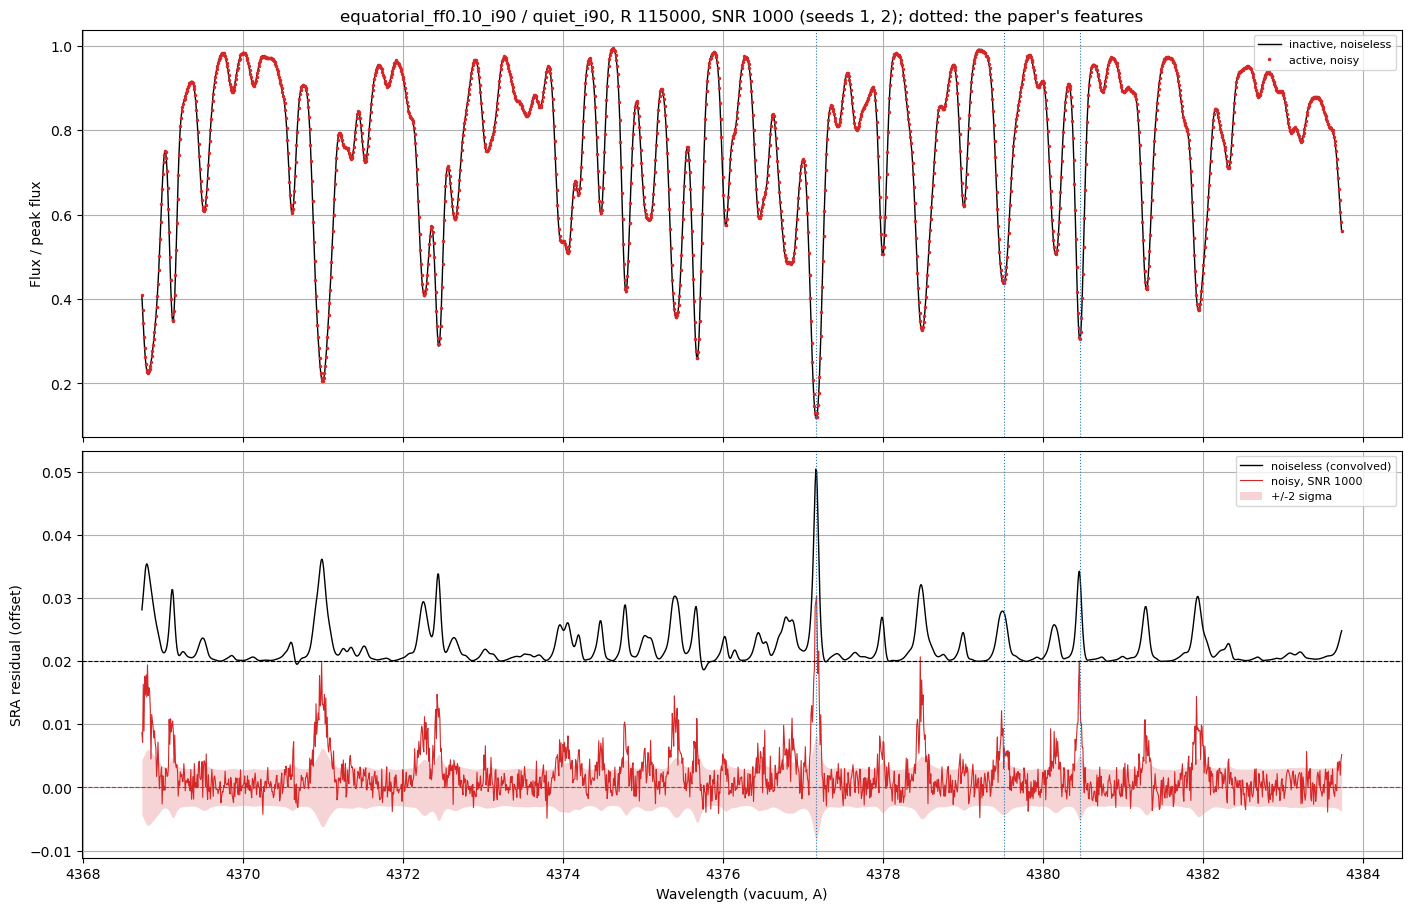

In [7]:
# ===== 7. plots =====
in_window = (wavelength >= plot_window[0]) & (wavelength <= plot_window[1])

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True, constrained_layout=True)
axes[0].plot(wavelength[in_window], norm_inactive_noiseless[in_window], color='k', linewidth=1, label='inactive, noiseless')
axes[0].plot(wavelength[in_window], norm_active[in_window], '.', color='tab:red', markersize=3, label='active, noisy')
axes[0].set_ylabel('Flux / peak flux')
offset = 0.02   # SRA units; on a grid line, so each dashed zero line sits on the grid
axes[1].plot(wavelength[in_window], sra_noiseless[in_window] + offset, color='k', linewidth=1,
             label='noiseless (convolved)')
axes[1].plot(wavelength[in_window], sra_noisy[in_window], color='tab:red', linewidth=0.8, label=f'noisy, SNR {snr}')
axes[1].fill_between(wavelength[in_window], -2 * sra_sigma[in_window], 2 * sra_sigma[in_window],
                     color='tab:red', alpha=0.2, linewidth=0, label='+/-2 sigma')
# Each curve's own zero, so its residual can be read off against its offset
for zero_level, zero_color in ((offset, 'k'), (0, 'tab:red')):
    axes[1].axhline(zero_level, color=zero_color, linestyle='--', linewidth=0.8)
axes[1].set_ylabel('SRA residual (offset)')
axes[1].set_xlabel('Wavelength (vacuum, A)')
for ax in axes:
    for feature_wavelength in paper_features.values():
        ax.axvline(feature_wavelength, color='tab:blue', linestyle=':', linewidth=0.8)
    ax.grid(True)
    ax.legend(fontsize=8)
axes[0].set_title(f"{contaminated_name} / {clean_name}, R {resolution}, SNR {snr} "
                  f"(seeds {seed_active}, {seed_inactive}); dotted: the paper's features")
plt.show()

SNR 200: Fe I 4375.9 (air) noiseless 0.0304, noise 0.0205 (1.5 sigma)
SNR 500: Fe I 4375.9 (air) noiseless 0.0304, noise 0.0082 (3.7 sigma)
SNR 1000: Fe I 4375.9 (air) noiseless 0.0304, noise 0.0041 (7.4 sigma)
SNR 3000: Fe I 4375.9 (air) noiseless 0.0304, noise 0.0014 (22.3 sigma)


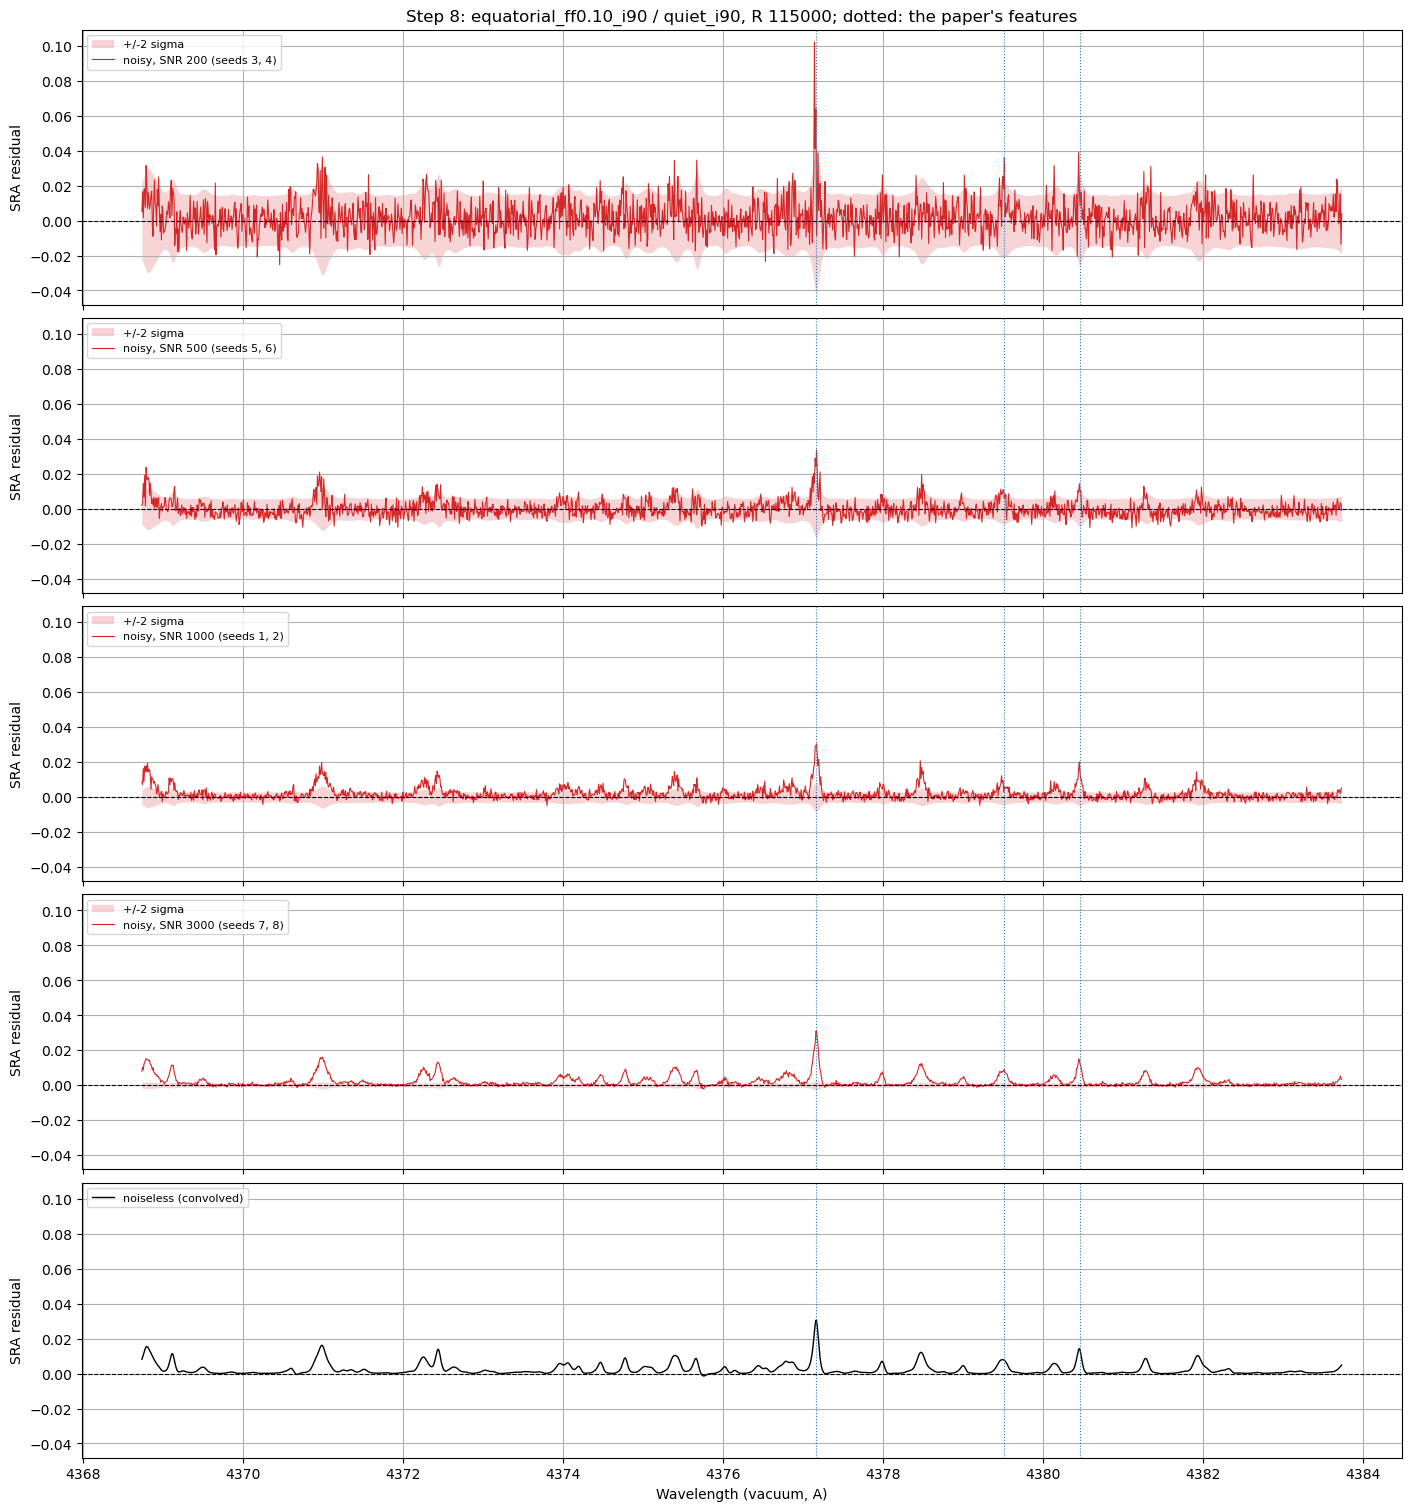

In [8]:
# ===== 8. SRA residual at SNR 200, 500, 1000 and 3000 =====
# Steps 4-6 repeated for each SNR with an independent noise draw per SNR, so panel-to-panel differences mix the SNR
# with random chance. SNR 1000 reuses the step-4 seeds, so its panel matches step 7.
comparison_seeds = {200: (3, 4), 500: (5, 6), 1000: (seed_active, seed_inactive), 3000: (7, 8)}   # snr: (active, inactive)


def noisy_spectrum(flux, snr_peak, seed):
    # Same photon-noise model as step 4: SNR per bin = snr_peak x sqrt(flux / peak flux)
    snr_per_bin = snr_peak * np.sqrt(flux / flux.max())
    return flux + np.random.default_rng(seed).normal(0, flux / snr_per_bin), snr_per_bin


# One panel per SNR, then the noiseless (convolved) SRA alone at the bottom
fig, axes = plt.subplots(len(comparison_seeds) + 1, 1, figsize=(14, 15), sharex=True, sharey=True,
                         constrained_layout=True)
for ax, (snr_peak, (seed_a, seed_i)) in zip(axes[:-1], comparison_seeds.items()):
    noisy_a, snr_a = noisy_spectrum(convolved_active, snr_peak, seed_a)
    noisy_i, snr_i = noisy_spectrum(convolved_inactive, snr_peak, seed_i)
    sra_snr = sra_residual(peak_normalised(noisy_a), peak_normalised(noisy_i))
    sigma_snr = np.sqrt(1 / snr_a ** 2 + 1 / snr_i ** 2)   # 1-sigma noise of the ratio
    print(f"SNR {snr_peak}: Fe I 4375.9 (air) noiseless {sra_noiseless[peak]:.4f}, noise {sigma_snr[peak]:.4f} "
          f"({sra_noiseless[peak] / sigma_snr[peak]:.1f} sigma)")

    ax.fill_between(wavelength[in_window], -2 * sigma_snr[in_window], 2 * sigma_snr[in_window],
                    color='tab:red', alpha=0.2, linewidth=0, label='+/-2 sigma')
    ax.plot(wavelength[in_window], sra_snr[in_window], color='tab:red', linewidth=0.8,
            label=f'noisy, SNR {snr_peak} (seeds {seed_a}, {seed_i})')
    ax.axhline(0, color='k', linestyle='--', linewidth=0.8)
axes[-1].plot(wavelength[in_window], sra_noiseless[in_window], color='k', linewidth=1, label='noiseless (convolved)')
axes[-1].axhline(0, color='k', linestyle='--', linewidth=0.8)
for ax in axes:
    mark_paper_features(ax)
    ax.set_ylabel('SRA residual')
    ax.grid(True)
    ax.legend(fontsize=8, loc='upper left')
axes[0].set_title(f"Step 8: {contaminated_name} / {clean_name}, R {resolution}; dotted: the paper's features")
axes[-1].set_xlabel('Wavelength (vacuum, A)')
plt.show()